# Многократные срабатывания одного ОМ: exp против muatm МС

Что разбираем: события, где один оптический модуль дал несколько импульсов (≥2). Вопрос —
что это за множество, чем exp отличается от МС, насколько пачка отстоит от основного облака
сигнальных срабатываний, как это зависит от её размера и заряда, и как это отражается на
скорe классификатора и на направлении трека.

**Определения, дальше они не меняются:**

- **пачка / повторившийся ОМ** — канал с ≥2 импульсами в одном событии; **n_max** — сколько
  импульсов у самого «болтливого» модуля события; **топ-ОМ** — этот модуль;
- **SN-сигнальный импульс** — `prob > 0.8` (тот же строгий порог, что в пайплайне);
- **top_sn_share** — доля импульсов топ-ОМ, помеченных SN-моделью сигнальными;
- **top_qsum / top_qmax** — суммарный и максимальный заряд импульсов топ-ОМ (п.е.);
  **q_per_pulse** = top_qsum / top_n — средний заряд импульса пачки;
- **облако** — SN-сигнальные хиты того же события, кроме топ-ОМ; **top_dist** — расстояние
  от топ-ОМ до ближайшего хита облака (трёхмерное, в системе координат хитов);
- **правда МС** — `raw/labels`: 0 = шум, <0 = свет мюонного трека, k·10⁶+j = свет ливня;
  **top_truth_noise** — доля импульсов топ-ОМ, которые по правде шум.

**Данные.** Признаки посчитаны скриптом `build_repeated_hit_features.py` по фиксированному
сэмплу: **четыре рана exp_full (11.0 млн событий) и 189 партов muatm (5.48 млн)** — ×2 и ×21
по событиям относительно первой версии (2 рана, 8 партов). Парты МС выбраны систематически;
сэмпл и все счётчики видны в первой таблице. Скор присоединён по `event_fk`; фит — из
каталога, который покрывает лишь часть событий, поэтому у большинства строк колонки фита NaN.

Расширение сэмпла важно: первая, малая выборка МС оказалась нерепрезентативной по хвосту
пачек — доля n_max ≥ 5 в h8s3 была 13 %, на 189 партах — 6 %. Все числа ниже пересчитаны
на расширенном сэмпле.

Порядок анализа: данные → проверки → **рабочая выборка h8s3** → что это за множество →
геометрия → заряд пачки → правда МС → скор → направление → итог. Все сравнения доменов делаются
внутри h8s3: на полном потоке они мерили бы состав триггера, а не физику (в exp
большинство событий — шум без мюонного аналога в МС).

In [1]:
import os, sys, json
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")
sys.path.insert(0, "/home/albert/Baikal2025")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.15, "axes.spines.top": False,
                     "axes.spines.right": False})

DATA = "repeated_hit_features/repeated_hit_features.parquet"
META = "repeated_hit_features/repeated_hit_features.json"
COLOURS = {"exp": "#d62728", "muatm": "#1f77b4"}
LABELS = {"exp": "exp_full", "muatm": "muatm МС"}

BLUE, RED, GREY = "#1f77b4", "#d62728", "#8c8c8c"

## 1. Данные и сэмпл

In [2]:
meta = json.load(open(META))
events = pd.read_parquet(DATA)
print(f"событий: {len(events):,}; экспорт из {meta['script']}, {meta['written']}, "
      f"commit {meta['git_commit'][:10]}")
print(f"сэмпл: exp_full {meta['exp_parts']}, muatm {meta['mc_parts']}")

sample = (events.groupby("domain")
          .agg(событий=("event_fk", "size"), партов=("part_key", "nunique"),
               хитов=("n_hits", "sum"),
               с_фитом=("fit_status", lambda s: int(s.eq("ok").sum())),
               со_скором=("score", lambda s: int(s.notna().sum())))
          .rename(index=LABELS))
sample

событий: 16,502,735; экспорт из inference/nu_classifier/analysis/HIGH_SCORE_EXCESS/build_repeated_hit_features.py, 2026-10-18T19:43:14, commit 6baec964e4
сэмпл: exp_full ['part_s2020_c04_r0031', 'part_s2020_c06_r0024', 'part_s2020_c02_r0055', 'part_s2020_c07_r0465'], muatm ['part_1002', 'part_10029', 'part_1004', 'part_10046', 'part_10049', 'part_1005', 'part_10057', 'part_1009', 'part_10002', 'part_10118', 'part_10213', 'part_10318', 'part_10425', 'part_10540', 'part_10652', 'part_10769', 'part_1086', 'part_10950', 'part_11062', 'part_11157', 'part_11268', 'part_11365', 'part_1146', 'part_11573', 'part_11671', 'part_11781', 'part_11877', 'part_11984', 'part_12069', 'part_12184', 'part_12288', 'part_12383', 'part_12479', 'part_1258', 'part_12674', 'part_12781', 'part_12862', 'part_12965', 'part_1306', 'part_1317', 'part_13273', 'part_13373', 'part_13472', 'part_13582', 'part_13691', 'part_13779', 'part_13875', 'part_13960', 'part_1407', 'part_14168', 'part_14268', 'part_14369', 'part_1

,событий,партов,хитов,с_фитом,со_скором
domain,,,,,
exp_full,11020499,4,571661567,104373,1194939
muatm МС,5482236,189,414337989,18683,1439834


## 2. Проверки, без которых числа не значат ничего

In [3]:
checks = []
checks.append(("событий загружено", f"{len(events):,}",
               len(events) == meta["events"]))
checks.append(("local_idx уникален внутри парта",
               "да", not events.duplicated(["part_key", "local_idx"]).any()))
have = events.dropna(subset=["n_sn_hits"])
checks.append(("n_sn == n_sn_hits из базы предсказаний",
               f"{(have.n_sn == have.n_sn_hits).mean():.4%} совпадений",
               (have.n_sn == have.n_sn_hits).all()))
checks.append(("импульсов на повторившихся ОМ <= всех импульсов",
               "да", bool((events.n_rep_pulses <= events.n_hits).all())))
checks.append(("топ-ОМ определён везде, где есть хиты",
               f"пустых событий: {int((events.n_hits == 0).sum())}",
               bool(((events.n_hits == 0) | (events.top_n == events.n_max)).all())))
checks.append(("правда МС есть только у muatm",
               "да", bool(events.loc[events.domain == "exp", "truth_noise_share"]
                          .isna().all())))
pd.DataFrame(checks, columns=["проверка", "результат", "прошла"]).set_index("проверка")

,результат,прошла
проверка,,
событий загружено,"16,502,735",True
local_idx уникален внутри парта,да,True
n_sn == n_sn_hits из базы предсказаний,100.0000% совпадений,True
импульсов на повторившихся ОМ <= всех импульсов,да,True
"топ-ОМ определён везде, где есть хиты",пустых событий: 0,True
правда МС есть только у muatm,да,True


## 3. Рабочая выборка — h8s3

**Почему не весь поток.** Потоки доменов устроены по-разному, и это видно сразу: медиана
числа SN-сигнальных хитов в событии — **0 в exp против 3 в МС**, доля событий с ≥5
SN-хитами — **10.8 % против 26.3 %**; медиана размера — 51 хит против 75. В exp поток в основном состоит из шумовых событий, у
которых нет мюонного аналога; в МС каждое событие содержит мюон. Сравнивать на таком
потоке доли пачек, сигнальность и скор — значит мерить состав триггера, а не физику.

**Что делаем.** Дальше все сравнения — на **h8s3**: ≥8 SN-сигнальных хитов на ≥3 струнах
(стандартный кат пайплайна). Это множество событий, где домены сопоставимы. Полный поток
остаётся только в этом разделе — как диагностика, объясняющая сам выбор.

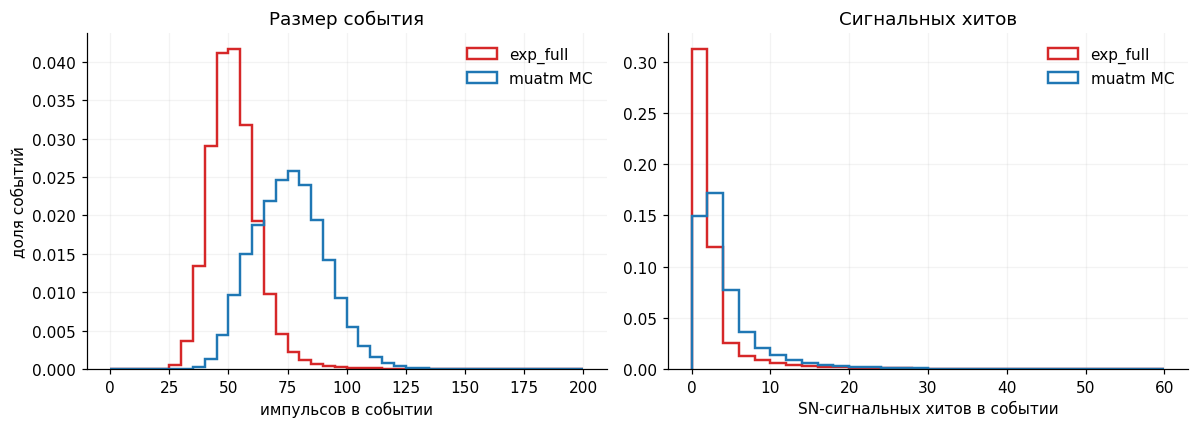

,событий,n_hits_медиана,n_sn_медиана,доля_n_sn_ge5
domain,,,,
exp_full,11020499,51.0,0.0,0.1084
muatm МС,5482236,75.0,3.0,0.2626


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for domain, colour in COLOURS.items():
    frame = events[events.domain == domain]
    axes[0].hist(frame.n_hits.clip(upper=200), bins=np.arange(0, 201, 5), density=True,
                 histtype="step", lw=1.6, color=colour, label=LABELS[domain])
    axes[1].hist(frame.n_sn.clip(upper=60), bins=np.arange(0, 61, 2), density=True,
                 histtype="step", lw=1.6, color=colour, label=LABELS[domain])
axes[0].set(xlabel="импульсов в событии", ylabel="доля событий")
axes[0].set_title("Размер события")
axes[0].legend(frameon=False)
axes[1].set(xlabel="SN-сигнальных хитов в событии")
axes[1].set_title("Сигнальных хитов")
axes[1].legend(frameon=False)
fig.tight_layout(); plt.show()

# доля событий с >=5 SN-хитами -- общая почва для сравнения доменов
pop = events.groupby("domain").agg(
    событий=("n_hits", "size"), n_hits_медиана=("n_hits", "median"),
    n_sn_медиана=("n_sn", "median"),
    доля_n_sn_ge5=("n_sn", lambda s: (s >= 5).mean())).rename(index=LABELS)
pop.round(4)

In [5]:
# Рабочая выборка: h8s3 -- >=8 SN-сигнальных хитов на >=3 струнах (кат пайплайна).
# n_sn и n_sn_strings взяты из базы предсказаний и сверены с пересчётом выше;
# у непроскоренных событий их нет (NaN), и кат отсекает их сам.
totals = events.groupby("domain").size()
work = events[(events.n_sn >= 8) & (events.n_sn_strings >= 3)].copy()
print(f"поток: {len(events):,} событий -> h8s3: {len(work):,}")
for domain, count in work.groupby("domain").size().items():
    print(f"  {LABELS[domain]}: {count:,} из {totals[domain]:,} "
          f"({count / totals[domain]:.1%} потока)")
print(f"с сошедшимся фитом: {int(work.fit_status.eq('ok').sum()):,}")

поток: 16,502,735 событий -> h8s3: 939,314
  exp_full: 497,473 из 11,020,499 (4.5% потока)
  muatm МС: 441,841 из 5,482,236 (8.1% потока)
с сошедшимся фитом: 66,364


В рабочую выборку попадает **4.5 % потока exp (497 473 события) и 8.1 % МС (441 841)**.
Дальше слово «события» всегда означает h8s3, если не сказано иное. Медианы размера в
выборке — 69 и 87 хитов, по 13 SN-хитов: размер сопоставим, но события МС в среднем крупнее,
поэтому ниже есть стратификация по n_hits.

Оговорка: сам кат h8s3 построен по SN-сигнальным хитам — той же величине, которую мы
дальше изучаем. Поэтому все доли читаются как «внутри отобранной выборки», а не как «доля
от потока»; и сама проходная доля h8s3 различается между доменами (4.5 % против 8.1 %) —
это свойство потока, а не вывод о пачках.

## 4. Что это за множество и как часто встречается

Все числа раздела — внутри **h8s3** (если не сказано иное).

In [6]:
# «Пачка» -- повторное срабатывание одного ОМ (>=2 импульсов). Рабочая выборка --
# h8s3 (определена выше), все доли считаются внутри неё. n_max -- сколько импульсов
# у самого «болтливого» модуля события.
def shares(frame):
    n = len(frame)
    return pd.Series({
        "событий": n,
        "n_max >= 2": (frame.n_max >= 2).mean(),
        "n_max >= 5": (frame.n_max >= 5).mean(),
        "n_max >= 10": (frame.n_max >= 10).mean(),
        "n_max >= 20": (frame.n_max >= 20).mean(),
        "доля импульсов на повторившихся ОМ": frame.n_rep_pulses.sum() / frame.n_hits.sum(),
        "медиана n_max (события с n_max>=2)": frame.loc[frame.n_max >= 2, "n_max"].median(),
        "SN-доля на топ-ОМ (все события с n_max>=2)": frame.loc[frame.n_max >= 2, "top_sn_share"].mean(),
    })

rates = pd.concat({LABELS[d]: shares(g) for d, g in work.groupby("domain")}, axis=1)
rates.loc["событий"] = rates.loc["событий"].astype(int)
rates

,exp_full,muatm МС
событий,497473.000000,441841.000000
n_max >= 2,0.999906,0.999919
n_max >= 5,0.132264,0.059902
n_max >= 10,0.008587,0.046551
n_max >= 20,0.000185,0.015220
доля импульсов на повторившихся ОМ,0.358576,0.314405
медиана n_max (события с n_max>=2),3.000000,3.000000
SN-доля на топ-ОМ (все события с n_max>=2),0.245502,0.164605


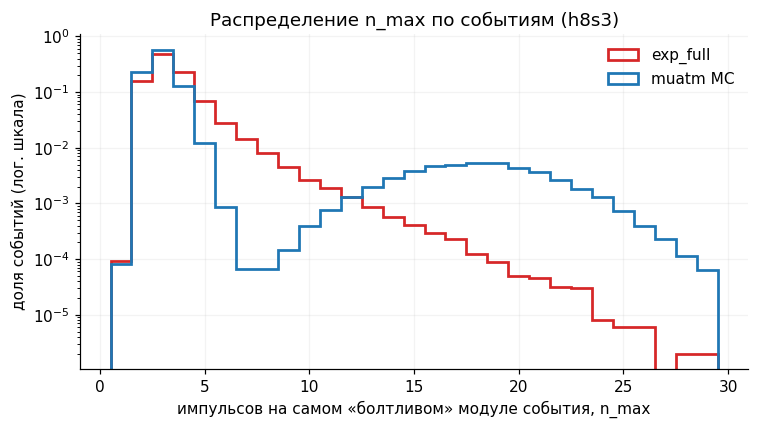

In [7]:
fig, axis = plt.subplots(figsize=(7, 4))
bins = np.arange(1, 31) - 0.5
for domain, colour in COLOURS.items():
    values = work.loc[work.domain == domain, "n_max"].clip(upper=30)
    axis.hist(values, bins=bins, density=True, histtype="step", lw=1.8,
              color=colour, label=LABELS[domain])
axis.set_yscale("log")
axis.set(xlabel="импульсов на самом «болтливом» модуле события, n_max",
         ylabel="доля событий (лог. шкала)")
axis.set_title("Распределение n_max по событиям (h8s3)")
axis.legend(frameon=False)
fig.tight_layout(); plt.show()

**Порог «пачка».** Внутри h8s3 при n_max ≥ 2 пачка есть практически в каждом событии
(99.99 % exp и МС). Дальше доли расходятся: n_max ≥ 5 — **13.2 % exp против 6.0 % МС**,
n_max ≥ 10 — **0.86 % против 4.66 %** (×5.4), n_max ≥ 20 — **0.019 % против 1.52 %** (×80).
Дальше «большой пачкой» называем n_max ≥ 10. Но события МС в h8s3 крупнее (медиана 87 хитов
против 69), а пачка тем вероятнее, чем больше хитов, поэтому смотрим доли внутри бинов по
размеру.

In [8]:
# Пачка -- отчасти свойство размера события: чем больше хитов, тем больше шансов, что
# какой-то модуль сработал много раз. Сравниваем домены внутри бинов по n_hits.
size_edges = [0, 50, 75, 100, 150, 250, 10_000]
size_labels = ["<50", "50–74", "75–99", "100–149", "150–249", "≥250"]
for domain in ("exp", "muatm"):
    frame = work[work.domain == domain].copy()
    frame["bin"] = pd.cut(frame.n_hits, size_edges, labels=size_labels, right=False)
    print(f"\n{LABELS[domain]}: доли событий с пачкой внутри бина по размеру")
    print(frame.groupby("bin", observed=True).agg(
        событий=("n_max", "size"),
        n_max_ge5=("n_max", lambda s: (s >= 5).mean()),
        n_max_ge10=("n_max", lambda s: (s >= 10).mean()),
        n_max_ge20=("n_max", lambda s: (s >= 20).mean()),
    ).round(4).to_string())


exp_full: доли событий с пачкой внутри бина по размеру
         событий  n_max_ge5  n_max_ge10  n_max_ge20
bin                                                
<50        17963     0.0228      0.0001      0.0000
50–74     304669     0.0889      0.0037      0.0000
75–99     147857     0.1958      0.0167      0.0004
100–149    25473     0.3297      0.0257      0.0010
150–249     1470     0.6293      0.0156      0.0007
≥250          41     0.9512      0.0488      0.0000

muatm МС: доли событий с пачкой внутри бина по размеру
         событий  n_max_ge5  n_max_ge10  n_max_ge20
bin                                                
<50          916     0.0011      0.0000      0.0000
50–74     105066     0.0322      0.0280      0.0037
75–99     230983     0.0755      0.0653      0.0220
100–149   103812     0.0528      0.0244      0.0119
150–249     1064     0.1541      0.0197      0.0085


**Что показывает стратификация.** При n_max ≥ 5 exp опережает МС в каждом бине размера
(например, 19.6 % против 7.6 % при 75–99 хитах). При n_max ≥ 10 картина другая: при
100–149 хитах доли почти равны (2.6 % против 2.4 %), при 50–99 МС даже выше. Устойчиво
МС опережает exp только в хвосте: n_max ≥ 20 — 0.4–2.2 % в зависимости от бина против
≤0.1 % в exp. То есть «большая пачка» как признак домена работает только в экстремальном
хвосте; средние пачки, наоборот, чаще в exp.

**Зависимость от размера пачки.** Проверяемая гипотеза: если пачки — шум, сеть не должна
звать их сигналом тем охотнее, чем они больше. Смотрим долю SN-сигнальных импульсов топ-ОМ
как функцию n_max.

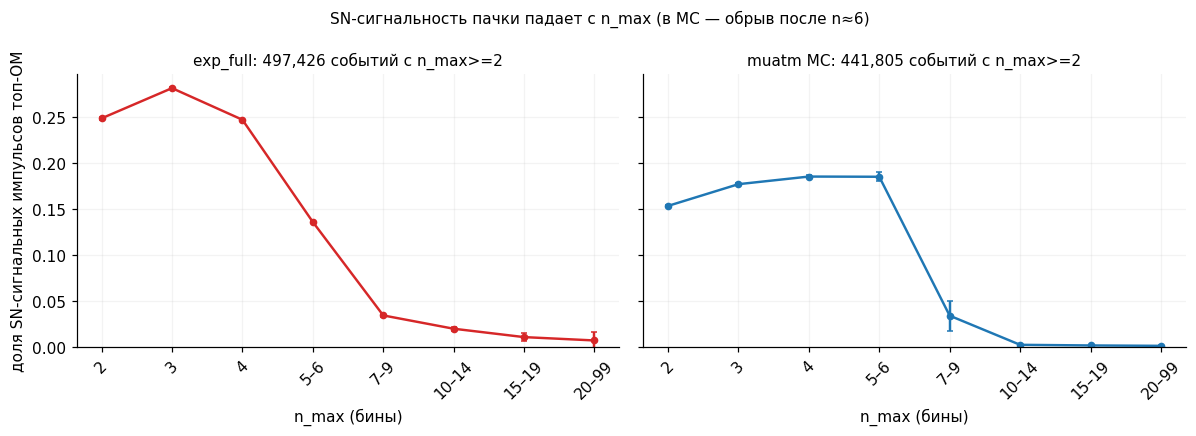

In [9]:
# Зависимость сигнальности от числа срабатываний: доля импульсов топ-ОМ с prob > 0.8.
edges = [2, 3, 4, 5, 7, 10, 15, 20, 100]
labels = [f"{a}" if b == a + 1 else f"{a}–{b - 1}" for a, b in zip(edges[:-1], edges[1:])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, domain in zip(axes, COLOURS):
    frame = work[(work.domain == domain) & (work.n_max >= 2)].copy()
    frame["bin"] = pd.cut(frame.n_max, edges, labels=labels, right=False)
    table = frame.groupby("bin", observed=True).agg(
        n=("top_sn_share", "size"),
        share=("top_sn_share", "mean"),
        err=("top_sn_share", lambda s: np.sqrt(max(s.mean() * (1 - s.mean()), 1e-12)
                                               / max(len(s), 1))))
    good = table[table.n >= 20]
    axis.errorbar(np.arange(len(good)), good.share, yerr=good.err, fmt="o-",
                  color=COLOURS[domain], lw=1.6, ms=4, capsize=2)
    axis.set_xticks(np.arange(len(good)), good.index, rotation=45)
    axis.set_title(f"{LABELS[domain]}: {len(frame):,} событий с n_max>=2", fontsize=10)
    axis.set_xlabel("n_max (бины)")
axes[0].set_ylabel("доля SN-сигнальных импульсов топ-ОМ")
axes[0].set_ylim(0, None)
fig.suptitle("SN-сигнальность пачки падает с n_max (в МС — обрыв после n≈6)", fontsize=10)
fig.tight_layout(); plt.show()

Гипотеза подтверждается с обратным знаком: с ростом n_max сигнальность **падает**, а не
растёт. Максимум — на малых пачках (2–4 импульса): 25–28 % в exp, 15–19 % в МС. В МС обрыв
после n ≈ 6–7: на бинах 10–15 и выше остаётся 0.15–0.27 % (бин 7–9 — 3.4 %, но там всего
124 события). В exp спад плавный, и на n ≥ 10 остаётся 0.7–2.0 % — в 5–8 раз выше, чем в МС.
Правило «большая пачка — шум» есть в обоих доменах, но в exp усвоено хуже.

## 5. Геометрия: далеко ли пачка от основного облака

In [10]:
# «Облако» -- SN-сигнальные хиты события, кроме самого топ-ОМ. top_dist -- расстояние
# от топ-ОМ до ближайшего такого хита. События без облака (top_dist = NaN) выпадают.
cloud = work[work.n_max >= 10].copy()
print(f"событий с пачкой n_max>=10: {len(cloud):,}; "
      f"с непустым облаком сигнальных хитов: {cloud.top_dist.notna().sum():,}")

table = cloud.groupby("domain").agg(
    n_с_облаком=("top_dist", "count"),
    медиана_м=("top_dist", "median"),
    доля_gt30=("top_dist", lambda s: (s > 30).mean()),
    доля_gt60=("top_dist", lambda s: (s > 60).mean()),
    доля_gt100=("top_dist", lambda s: (s > 100).mean()),
).rename(index=LABELS)
print("\nвсе события с пачкой n_max>=10:")
print(table.round(3).to_string())

событий с пачкой n_max>=10: 24,840; с непустым облаком сигнальных хитов: 24,840

все события с пачкой n_max>=10:
          n_с_облаком  медиана_м  доля_gt30  доля_gt60  доля_gt100
domain                                                            
exp_full         4272     93.263      0.835      0.659       0.474
muatm МС        20568     95.851      0.951      0.764       0.480


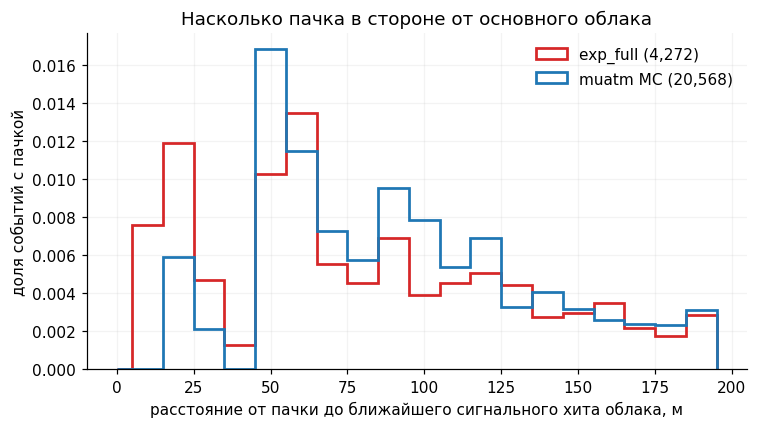

In [11]:
fig, axis = plt.subplots(figsize=(7, 4))
bins = np.concatenate([[0], np.arange(5, 201, 10)])
for domain, colour in COLOURS.items():
    values = cloud.loc[cloud.domain == domain, "top_dist"].dropna()
    axis.hist(values.clip(upper=200), bins=bins, density=True, histtype="step",
              lw=1.8, color=colour, label=f"{LABELS[domain]} ({len(values):,})")
axis.set(xlabel="расстояние от пачки до ближайшего сигнального хита облака, м",
         ylabel="доля событий с пачкой")
axis.set_title("Насколько пачка в стороне от основного облака")
axis.legend(frameon=False)
fig.tight_layout(); plt.show()

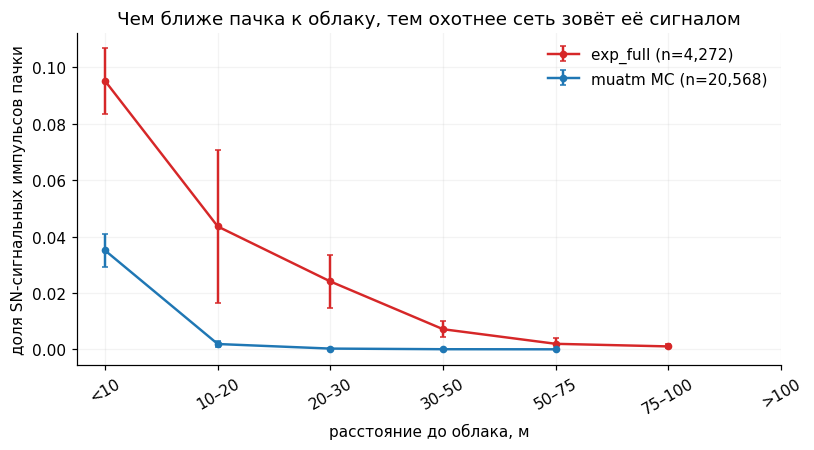

In [12]:
edges = [0, 10, 20, 30, 50, 75, 100, 2000]
labels = ["<10", "10–20", "20–30", "30–50", "50–75", "75–100", ">100"]
fig, axis = plt.subplots(figsize=(7.5, 4.2))
for domain, colour in COLOURS.items():
    frame = cloud[cloud.domain == domain].dropna(subset=["top_dist"]).copy()
    frame["bin"] = pd.cut(frame.top_dist, edges, labels=labels, right=False)
    table = frame.groupby("bin", observed=True).agg(
        n=("top_sn_share", "size"), share=("top_sn_share", "mean"))
    table["err"] = np.sqrt(table.share * (1 - table.share) / table.n)
    good = table[table.n >= 20]
    axis.errorbar(np.arange(len(good)), good.share, yerr=good.err, fmt="o-",
                  color=colour, lw=1.6, ms=4, capsize=2,
                  label=f"{LABELS[domain]} (n={good.n.sum():,})")
axis.set_xticks(np.arange(len(labels)), labels, rotation=30)
axis.set(xlabel="расстояние до облака, м",
         ylabel="доля SN-сигнальных импульсов пачки")
axis.set_title("Чем ближе пачка к облаку, тем охотнее сеть зовёт её сигналом")
axis.legend(frameon=False)
fig.tight_layout(); plt.show()

## 6. Заряд пачки

Заряд Q в п.е. Смотрим две величины: **top_qmax** — максимальный заряд одного импульса
топ-ОМ и **top_qsum** — суммарный заряд всех его импульсов; **q_per_pulse** = top_qsum /
top_n — средний заряд импульса пачки. Вопросы: чем заряд отличается между доменами, как
он меняется с размером пачки, и что с ним делают SN-модель и классификатор.

In [13]:
# Заряд топ-ОМ: top_qsum -- сумма Q всех его импульсов, top_qmax -- максимальный
# заряд одного импульса (п.е.); q_per_pulse -- средний заряд импульса пачки.
work["q_per_pulse"] = work.top_qsum / work.top_n

def charge_table(frame):
    return frame.groupby("domain").agg(
        событий=("top_qmax", "size"),
        n_max_медиана=("n_max", "median"),
        qmax_медиана=("top_qmax", "median"),
        qmax_q25=("top_qmax", lambda s: s.quantile(0.25)),
        qmax_q75=("top_qmax", lambda s: s.quantile(0.75)),
        qsum_медиана=("top_qsum", "median"),
        q_на_импульс=("q_per_pulse", "median"),
    ).rename(index=LABELS)

print("вся выборка h8s3:")
print(charge_table(work).round(2).to_string())
print("\nтолько большие пачки (n_max >= 10):")
print(charge_table(work[work.n_max >= 10]).round(2).to_string())

# как заряд меняется с размером пачки
edges = [2, 3, 4, 5, 7, 10, 15, 20, 100]
bin_labels = [f"{a}" if b == a + 1 else f"{a}–{b - 1}"
              for a, b in zip(edges[:-1], edges[1:])]
for domain in ("exp", "muatm"):
    frame = work[(work.domain == domain) & (work.n_max >= 2)].copy()
    frame["bin"] = pd.cut(frame.n_max, edges, labels=bin_labels, right=False)
    print(f"\n{LABELS[domain]}: медианы заряда по размеру пачки")
    print(frame.groupby("bin", observed=True).agg(
        n=("n_max", "size"), qmax=("top_qmax", "median"),
        q_на_импульс=("q_per_pulse", "median")).round(2).to_string())

вся выборка h8s3:
          событий  n_max_медиана  qmax_медиана  qmax_q25  qmax_q75  qsum_медиана  q_на_импульс
domain                                                                                        
exp_full   497473            3.0          1.74      1.24      4.43          4.12          1.19
muatm МС   441841            3.0          1.35      1.07      2.17          2.96          0.99

только большие пачки (n_max >= 10):
          событий  n_max_медиана  qmax_медиана  qmax_q25  qmax_q75  qsum_медиана  q_на_импульс
domain                                                                                        
exp_full     4272           11.0          3.67      2.32      7.50         15.82          1.33
muatm МС    20568           18.0          2.55      2.06      3.31         18.94          1.05



exp_full: медианы заряда по размеру пачки
            n  qmax  q_на_импульс
bin                              
2       79751  1.30          1.07
3      239656  1.67          1.19
4      112221  2.22          1.29
5–6     48278  2.31          1.25
7–9     13248  2.48          1.23
10–14    3608  3.39          1.30
15–19     572  5.54          1.49
20–99      92  7.60          1.54

muatm МС: медианы заряда по размеру пачки
            n  qmax  q_на_импульс
bin                              
2      102840  1.17          0.95
3      255989  1.35          0.99
4       56509  1.50          1.02
5–6      5775  1.66          1.04
7–9       124  1.96          1.01
10–14    3240  2.35          1.05
15–19   10603  2.53          1.05
20–99    6725  2.66          1.04


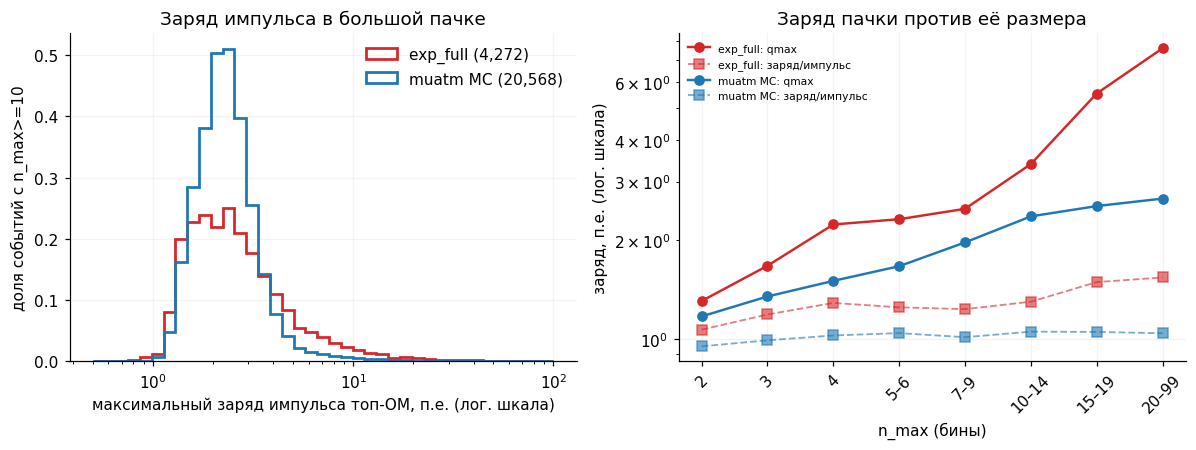

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
# (a) заряд импульса в большой пачке: exp -- ярче и шире, МС -- тусклее и уже
bins = np.logspace(np.log10(0.5), np.log10(100), 40)
for domain, colour in COLOURS.items():
    values = work.loc[(work.domain == domain) & (work.n_max >= 10), "top_qmax"].dropna()
    axes[0].hist(values, bins=bins, density=True, histtype="step", lw=1.8,
                 color=colour, label=f"{LABELS[domain]} ({len(values):,})")
axes[0].set_xscale("log")
axes[0].set(xlabel="максимальный заряд импульса топ-ОМ, п.е. (лог. шкала)",
            ylabel="доля событий с n_max>=10")
axes[0].set_title("Заряд импульса в большой пачке")
axes[0].legend(frameon=False)

# (b) медианы qmax и заряда на импульс против n_max
for domain, colour in COLOURS.items():
    frame = work[(work.domain == domain) & (work.n_max >= 2)].copy()
    frame["bin"] = pd.cut(frame.n_max, edges, labels=bin_labels, right=False)
    table = frame.groupby("bin", observed=True).agg(
        n=("top_qmax", "size"), qmax=("top_qmax", "median"),
        qpp=("q_per_pulse", "median"))
    good = table[table.n >= 20]
    x = np.asarray(good.index.codes)
    axes[1].plot(x, good.qmax, "o-", color=colour, lw=1.6,
                 label=f"{LABELS[domain]}: qmax")
    axes[1].plot(x, good.qpp, "s--", color=colour, lw=1.2, alpha=0.6,
                 label=f"{LABELS[domain]}: заряд/импульс")
axes[1].set_xticks(np.arange(len(bin_labels)), bin_labels, rotation=45)
axes[1].set_yscale("log")
axes[1].set(xlabel="n_max (бины)", ylabel="заряд, п.е. (лог. шкала)")
axes[1].set_title("Заряд пачки против её размера")
axes[1].legend(fontsize=7, frameon=False)
fig.tight_layout(); plt.show()

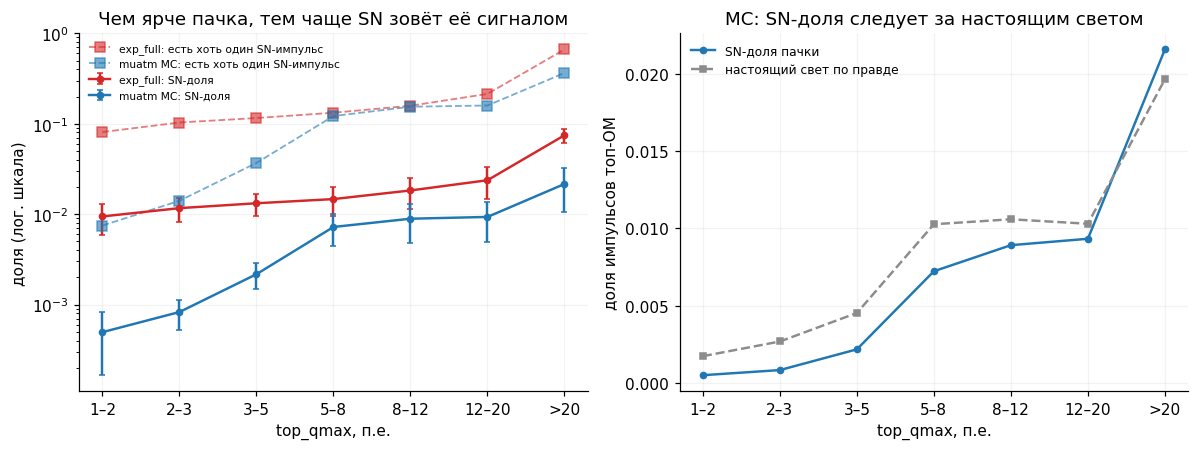

In [15]:
# Как заряд пачки связан с SN-предсказаниями и (в МС) с правдой
q_edges = [1, 2, 3, 5, 8, 12, 20, np.inf]
q_labels = ["1–2", "2–3", "3–5", "5–8", "8–12", "12–20", ">20"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) SN-доля и доля пачек с хоть одним SN-импульсом
for domain, colour in COLOURS.items():
    frame = work[(work.domain == domain) & (work.n_max >= 10)].copy()
    frame["bin"] = pd.cut(frame.top_qmax, q_edges, labels=q_labels, right=False)
    table = frame.groupby("bin", observed=True).agg(
        n=("top_sn_share", "size"), sn=("top_sn_share", "mean"),
        any_sn=("top_sn_share", lambda s: (s > 0).mean()))
    table["err"] = np.sqrt(table.sn * (1 - table.sn) / table.n)
    good = table[table.n >= 20]
    x = np.asarray(good.index.codes)
    axes[0].errorbar(x, good.sn, yerr=good.err, fmt="o-", color=colour, lw=1.6,
                     ms=4, capsize=2, label=f"{LABELS[domain]}: SN-доля")
    axes[0].plot(x, good.any_sn, "s--", color=colour, lw=1.2, alpha=0.6,
                 label=f"{LABELS[domain]}: есть хоть один SN-импульс")
axes[0].set_xticks(np.arange(len(q_labels)), q_labels)
axes[0].set_yscale("log")
axes[0].set(xlabel="top_qmax, п.е.", ylabel="доля (лог. шкала)")
axes[0].set_title("Чем ярче пачка, тем чаще SN зовёт её сигналом")
axes[0].legend(fontsize=7, frameon=False)

# (b) МС: SN-доля против доли настоящего света (1 - шум по правде)
frame = work[(work.domain == "muatm") & (work.n_max >= 10)].copy()
frame["bin"] = pd.cut(frame.top_qmax, q_edges, labels=q_labels, right=False)
table = frame.groupby("bin", observed=True).agg(
    n=("top_sn_share", "size"), sn=("top_sn_share", "mean"),
    truth_signal=("top_truth_noise", lambda s: (1 - s).mean()))
good = table[table.n >= 20]
x = np.asarray(good.index.codes)
axes[1].plot(x, good.sn, "o-", color=COLOURS["muatm"], lw=1.6, ms=4,
             label="SN-доля пачки")
axes[1].plot(x, good.truth_signal, "s--", color=GREY, lw=1.6, ms=4,
             label="настоящий свет по правде")
axes[1].set_xticks(np.arange(len(q_labels)), q_labels)
axes[1].set(xlabel="top_qmax, п.е.", ylabel="доля импульсов топ-ОМ")
axes[1].set_title("МС: SN-доля следует за настоящим светом")
axes[1].legend(fontsize=8, frameon=False)
fig.tight_layout(); plt.show()

In [16]:
# Скор события против заряда топ-ОМ (все события h8s3 с n_max>=2)
def score_by_charge(domain):
    frame = work[(work.domain == domain) & (work.n_max >= 2)].dropna(subset=["score"]).copy()
    frame["bin"] = pd.cut(frame.top_qmax, [0, 1, 2, 3, 5, 8, 12, 20, np.inf],
                          labels=["<1"] + q_labels, right=False)
    return frame.groupby("bin", observed=True).agg(
        событий=("score", "size"), медиана=("score", "median"),
        доля_gt0p5=("score", lambda s: (s > 0.5).mean()),
        доля_gt0p8=("score", lambda s: (s > 0.8).mean()))

print("exp_full:")
print(score_by_charge("exp").round(4).to_string())
print("\nmuatm МС:")
print(score_by_charge("muatm").round(4).to_string())

exp_full:
       событий  медиана  доля_gt0p5  доля_gt0p8
bin                                            
<1       52078   0.0141      0.0060      0.0013
1–2     223546   0.0138      0.0053      0.0011
2–3      57374   0.0135      0.0046      0.0010
3–5      51061   0.0134      0.0040      0.0006
5–8      37499   0.0135      0.0043      0.0009
8–12     24750   0.0134      0.0043      0.0005
12–20    23364   0.0133      0.0047      0.0012
>20      27754   0.0130      0.0084      0.0022

muatm МС:


       событий  медиана  доля_gt0p5  доля_gt0p8
bin                                            
<1       83038   0.0137      0.0036      0.0007
1–2     237618   0.0136      0.0036      0.0007
2–3      44938   0.0133      0.0029      0.0005
3–5      31973   0.0132      0.0024      0.0004
5–8      18632   0.0132      0.0019      0.0005
8–12     10698   0.0131      0.0029      0.0012
12–20     8385   0.0130      0.0033      0.0011
>20       6523   0.0126      0.0037      0.0008


**Что видно.** (i) Домены различаются уже по заряду: в целом по h8s3 медиана максимального
импульса топ-ОМ — **1.74 п.е. в exp против 1.35 п.е. в МС**, средний заряд импульса —
1.19 против 0.99. У больших пачек (n_max ≥ 10) различие качественное: в exp медиана qmax
**3.67 п.е.** при широком разбросе (IQR 2.32–7.50), в МС — **2.55 п.е.** при узком
(IQR 2.06–3.31). При этом МС-пачка в медиане длиннее (18 импульсов против 11), поэтому её
суммарный заряд даже выше (18.94 против 15.82 п.е.) — но набран он многими тусклыми
импульсами: заряд на импульс 1.05 п.е. против 1.33 в exp.
(ii) С ростом пачки заряд ведёт себя по-разному: в exp qmax растёт с 1.30 до 7.60 п.е., а
заряд на импульс — с 1.07 до 1.54; в МС qmax растёт слабее (1.17 → 2.66), а заряд на импульс
практически не меняется (0.95 → 1.04). То есть редкие большие пачки exp — это яркие
импульсы, а большие пачки МС — много тусклых (хвостовые бины exp: 572 события при
n_max 15–19 и 92 при 20–99).
(iii) SN-модель заряд использует: среди пачек n_max ≥ 10 доля SN-сигнальных импульсов
растёт с 0.94 % (qmax 1–2 п.е.) до 7.46 % (>20 п.е.) в exp и с 0.05 % до 2.16 % в МС, а доля
пачек, где сеть пометила хоть один импульс, — с 8.1 % до 66.3 % (exp) и с 0.75 % до 36.4 %
(МС).
(iv) Это не просто «яркое = сигнал»: в МС SN-доля в пачке идёт следом за долей настоящего
света по правде (0.17–1.96 %), составляя 30–110 % от неё: сеть реагирует на реальный свет
в ярких пачках, а в самом ярком бине даже слегка перебирает.
(v) На скор события заряд топ-ОМ не влияет: медиана скора во всех бинах qmax —
0.0126–0.0141, доля >0.8 меняется в пределах 0.04–0.22 % без монотонного тренда.

## 7. Что это по правде (только МС)

In [17]:
# По правде МС: 0 = шум, <0 = свет мюонного трека (raw/labels). Сравниваем, что сеть
# называет сигналом, с тем, что шум по правде.
mc = cloud[cloud.domain == "muatm"].dropna(subset=["top_truth_noise"]).copy()
print(f"порог пачки: n_max >= 10")
mc["sn_says_signal"] = mc.top_sn_share > 0   # сеть пометила хоть один импульс
mc["truth_says_noise"] = mc.top_truth_noise > 0.99  # пачка почти вся -- шум
print(f"МС-событий с пачкой и правдой: {len(mc):,}")
print("топ-ОМ: сеть пометила хоть один импульс x правда-шум > 99%:")
print(pd.crosstab(mc.truth_says_noise, mc.sn_says_signal,
                  rownames=["правда: шум"], colnames=["сеть: сигнал"]).to_string())
print(f"\nдоля SN-сигнальных импульсов в пачке: медиана {mc.top_sn_share.median():.3f}")
print(f"доля шумовых по правде:              медиана {mc.top_truth_noise.median():.3f}")

# связь сигнальности и правды по бинам расстояния
mc["bin"] = pd.cut(mc.top_dist, [0, 20, 30, 50, 75, 100, 2000],
                   labels=["<20", "20–30", "30–50", "50–75", "75–100", ">100"])
truth_table = mc.groupby("bin", observed=True).agg(
    событий=("top_sn_share", "size"),
    SN_сигнальных_в_пачке=("top_sn_share", "mean"),
    шум_по_правде_в_пачке=("top_truth_noise", "mean"))
truth_table

порог пачки: n_max >= 10
МС-событий с пачкой и правдой: 20,568
топ-ОМ: сеть пометила хоть один импульс x правда-шум > 99%:
сеть: сигнал  False  True 
правда: шум               
False           720    555
True          19179    114

доля SN-сигнальных импульсов в пачке: медиана 0.000
доля шумовых по правде:              медиана 1.000


,событий,SN_сигнальных_в_пачке,шум_по_правде_в_пачке
bin,,,
<20,1009,0.035060,0.958738
30–50,1532,0.001876,0.989964
50–75,4902,0.000252,0.996515
75–100,3249,0.000032,0.999404
>100,9876,0.000000,0.999894


## 8. Скор классификатора

In [18]:
# Скор nu-classifier: события с пачкой против событий без неё, и отдельно -- с далёкой.
work["big"] = work.n_max >= 10
work["far"] = work.big & (work.top_dist > 60)
score_table = (work.dropna(subset=["score"])
               .assign(group=lambda f: np.select(
                   [~f.big, f.big & ~f.far], ["n_max<10", "пачка n>=10 близко"],
                   "пачка n>=10 дальше 60 м"))
               .groupby(["domain", "group"])
               .agg(событий=("score", "size"), медиана=("score", "median"),
                    доля_gt0p5=("score", lambda s: (s > 0.5).mean()),
                    доля_gt0p8=("score", lambda s: (s > 0.8).mean()))
               .round(4))
score_table

событий  медиана  доля_gt0p5  доля_gt0p8
domain group                                                            
exp    n_max<10                  493201   0.0136      0.0052      0.0011
       пачка n>=10 близко          1458   0.0129      0.0075      0.0007
       пачка n>=10 дальше 60 м     2814   0.0138      0.0085      0.0018
muatm  n_max<10                  421273   0.0135      0.0033      0.0007
       пачка n>=10 близко          4846   0.0130      0.0019      0.0002
       пачка n>=10 дальше 60 м    15722   0.0135      0.0041      0.0006

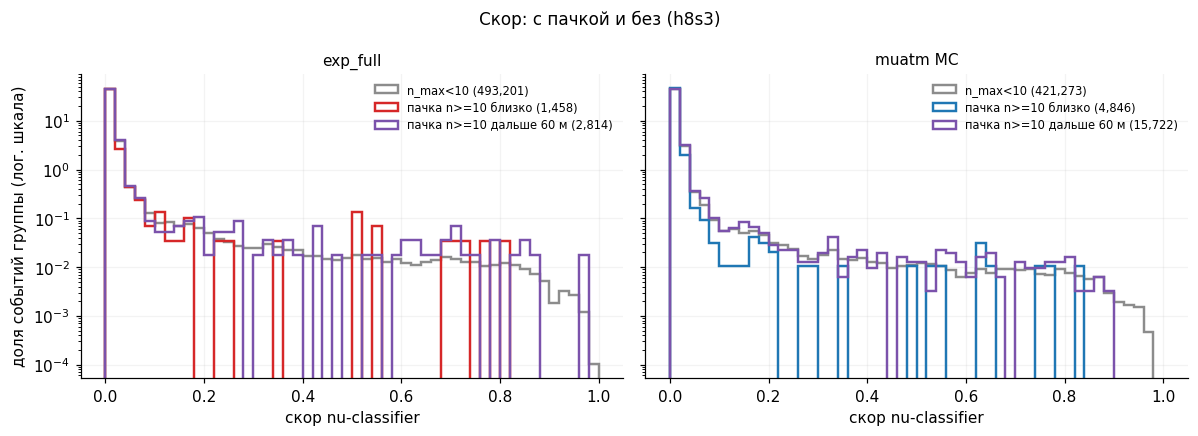

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
bins = np.linspace(0, 1, 51)
for axis, domain in zip(axes, COLOURS):
    frame = work[(work.domain == domain)].dropna(subset=["score"])
    for label, mask, colour in (("n_max<10", ~frame.big, GREY),
                                ("пачка n>=10 близко", frame.big & ~frame.far,
                                 COLOURS[domain]),
                                ("пачка n>=10 дальше 60 м", frame.far, "#7b52ab")):
        values = frame.loc[mask, "score"]
        axis.hist(values, bins=bins, density=True, histtype="step", lw=1.6,
                  color=colour, label=f"{label} ({len(values):,})")
    axis.set_yscale("log")
    axis.set_title(LABELS[domain], fontsize=10)
    axis.set_xlabel("скор nu-classifier")
    axis.legend(fontsize=7.5, frameon=False)
axes[0].set_ylabel("доля событий группы (лог. шкала)")
fig.suptitle("Скор: с пачкой и без (h8s3)", fontsize=11)
fig.tight_layout(); plt.show()

## 9. Направление трека (МС)

In [20]:
# МС: угол между треком нашего фита и истинным направлением мюона (prime_prty, град.).
ok = work[(work.domain == "muatm") & work.fit_status.eq("ok")
            & work.prime_theta.notna()].dropna(subset=["fit_theta_rec"]).copy()
def unit(theta_deg, phi_deg):
    th, ph = np.radians(theta_deg), np.radians(phi_deg)
    return np.stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)],
                    axis=-1)
cos = (unit(ok.fit_theta_rec, ok.fit_phi_rec) * unit(ok.prime_theta, ok.prime_phi)).sum(1)
ok["angle_err"] = np.degrees(np.arccos(np.clip(cos, -1, 1)))
ok["big"] = ok.n_max >= 10
ok["far"] = ok.big & (ok.top_dist > 60)
ok["group"] = np.select([~ok.big, ok.big & ~ok.far],
                        ["n_max<10", "пачка n>=10 близко"], "пачка n>=10 дальше 60 м")
direction = ok.groupby("group").agg(
    событий=("angle_err", "size"),
    медиана_угла=("angle_err", "median"),
    доля_gt10=("angle_err", lambda s: (s > 10).mean()),
    медиана_скора=("score", "median"))
print(f"МС-событий с фитом и правдой: {len(ok):,}")
direction

МС-событий с фитом и правдой: 8,032


,событий,медиана_угла,доля_gt10,медиана_скора
group,,,,
n_max<10,7541,10.927267,0.541440,0.013418
пачка n>=10 близко,113,10.525616,0.522124,0.013015
пачка n>=10 дальше 60 м,378,11.154680,0.550265,0.013647


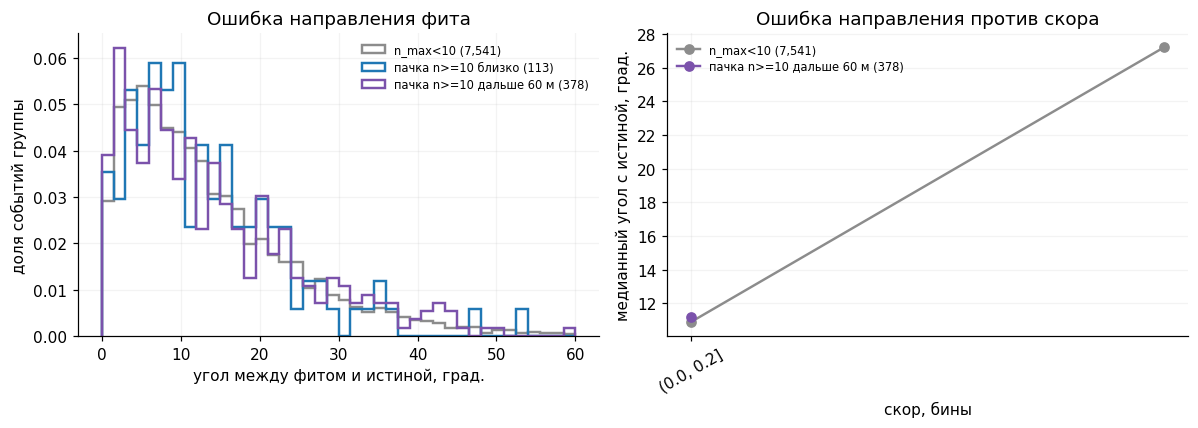

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 60, 41)
for label, colour in (("n_max<10", GREY), ("пачка n>=10 близко", BLUE),
                      ("пачка n>=10 дальше 60 м", "#7b52ab")):
    values = ok.loc[ok.group == label, "angle_err"]
    axes[0].hist(values, bins=bins, density=True, histtype="step", lw=1.6,
                 color=colour, label=f"{label} ({len(values):,})")
axes[0].set(xlabel="угол между фитом и истиной, град.", ylabel="доля событий группы")
axes[0].set_title("Ошибка направления фита")
axes[0].legend(fontsize=7.5, frameon=False)

# скор против ошибки направления, по группам
for label, colour in (("n_max<10", GREY), ("пачка n>=10 дальше 60 м", "#7b52ab")):
    frame = ok[ok.group == label]
    table = frame.groupby(pd.cut(frame.score, [0, 0.2, 0.5, 0.8, 1.0]),
                          observed=True).agg(err=("angle_err", "median"),
                                             n=("angle_err", "size"))
    table = table[table.n >= 20]
    axes[1].plot(np.arange(len(table)), table.err, "o-", color=colour, lw=1.6,
                 label=f"{label} ({len(frame):,})")
    axes[1].set_xticks(np.arange(len(table)), [str(i) for i in table.index], rotation=30)
axes[1].set(xlabel="скор, бины", ylabel="медианный угол с истиной, град.")
axes[1].set_title("Ошибка направления против скора")
axes[1].legend(fontsize=7.5, frameon=False)
fig.tight_layout(); plt.show()

## 10. Сводка чисел

In [22]:
# Числа для выводов, одним кадром: доли по доменам и по группам скора.
summary = pd.DataFrame({
    "всего": work.groupby("domain").size(),
    "пачка n>=10": work[work.big].groupby("domain").size(),
    "пачка n>=10 и дальше 60 м": work[work.far].groupby("domain").size(),
    "скор>0.8": work[work.score > 0.8].groupby("domain").size(),
    "скор>0.8 и пачка>60 м": work[(work.score > 0.8) & work.far].groupby("domain").size(),
}).rename(index=LABELS).fillna(0).astype(int)
summary["доля пачек среди всех"] = (summary["пачка n>=10"] / summary["всего"]).round(4)
summary["доля дальних среди пачек"] = (
    summary["пачка n>=10 и дальше 60 м"] / summary["пачка n>=10"].replace(0, np.nan)).round(3)
summary["доля скор>0.8"] = (summary["скор>0.8"] / summary["всего"]).round(4)
summary["доля скор>0.8 среди дальних"] = (
    summary["скор>0.8 и пачка>60 м"] / summary["пачка n>=10 и дальше 60 м"].replace(0, np.nan)).round(3)
summary

,всего,пачка n>=10,пачка n>=10 и дальше 60 м,скор>0.8,скор>0.8 и пачка>60 м,доля пачек среди всех,доля дальних среди пачек,доля скор>0.8,доля скор>0.8 среди дальних
domain,,,,,,,,,
exp_full,497473,4272,2814,538,5,0.0086,0.659,0.0011,0.002
muatm МС,441841,20568,15722,304,10,0.0466,0.764,0.0007,0.001


## 11. Что видно — с числами и оговорками

Все числа раздела — внутри **h8s3** (497 473 события exp, 441 841 МС), если не сказано иное.

1. **Малые пачки — общее свойство, средние чаще в exp.** n_max ≥ 2 практически в каждом
   событии (99.99 % exp и МС), медиана n_max = 3 в обоих. Но уже n_max ≥ 5: **13.2 % exp
   против 6.0 % МС**, и это не эффект размера — внутри каждого бина по n_hits exp опережает
   МС (например, 19.6 % против 7.6 % при 75–99 хитах). Доля импульсов на повторившихся ОМ:
   35.9 % exp против 31.4 % МС.
2. **Хвост: сырые доли выглядят как ×5 и ×80, но при ≥10 главную роль играет размер
   события.** n_max ≥ 10: 0.86 % exp против 4.66 % МС (×5.4); n_max ≥ 20: 0.019 % против
   1.52 % (×80). МС-события в h8s3 крупнее (медиана 87 хитов против 69), а пачка растёт с
   размером, поэтому после стратификации по n_hits различие при ≥10 почти исчезает: при
   100–149 хитах 2.6 % против 2.4 %, при 150–249 — 1.6 % против 2.0 %, а при 50–99 МС даже
   выше. Устойчивым остаётся только экстремальный хвост: n_max ≥ 20 — 0.4–2.2 % в МС в
   зависимости от бина против ≤0.1 % в exp. Причина (физика, модель отклика, симуляция
   послеимпульсов) этим срезом не устанавливается.
3. **В МС большие пачки — шум по правде, и в основном сеть это знает.** Из 20 568 МС-пачек
   n_max ≥ 10 у 19 293 (93.8 %) доля шумовых импульсов по правде > 99 %; медиана SN-доли
   пачки — 0.000. Сеть пометила хоть один импульс у 669 пачек: 555 из них — пачки с настоящим
   светом (точность 83 %), 114 — шумовые (0.59 % всех шумовых пачек). Обратно, сеть пометила
   555 из 1 275 пачек с настоящим светом (44 %). По расстоянию согласие полное: у облака
   (<20 м) SN-доля 3.5 % при шуме по правде 95.9 %, дальше 100 м — 0.000 и 99.99 %.
4. **Заряд пачки: exp — яркие импульсы, МС — много тусклых.** У больших пачек (n_max ≥ 10)
   медиана максимального импульса 3.67 п.е. в exp против 2.55 в МС, разброс шире
   (IQR 2.32–7.50 против 2.06–3.31); МС-пачка длиннее (18 против 11 импульсов), и её
   суммарный заряд выше (18.94 против 15.82 п.е.), но набран он импульсами по ~1.05 п.е.
   С ростом n_max в exp растут и qmax (1.30 → 7.60), и заряд на импульс (1.07 → 1.54);
   в МС заряд на импульс почти постоянен (0.95 → 1.04). SN-модель заряд использует:
   доля пачек с хоть одним SN-импульсом растёт с 8 % до 66 % (exp) и с 0.8 % до 36 % (МС)
   при qmax от 1–2 до >20 п.е., но в МС этот рост следует за долей настоящего света по
   правде (30–110 % от неё) — сеть реагирует на свет, а не на заряд. На скор события заряд
   топ-ОМ не влияет: медиана 0.0126–0.0141 во всех бинах.
5. **Геометрия: большая пачка в обоих доменах стоит в стороне от облака.** Медиана ~93–96 м;
   дальше 30 м — 84 % exp против 95 % МС; дальше 100 м — по 47–48 %. Различие умеренное
   и не в пользу «exp уникален».
6. **В сопоставимой популяции пачка скор не поднимает.** Доля событий со скором >0.8: exp —
   0.11 % без большой пачки, 0.07 % с близкой, 0.18 % с далёкой; МС — 0.07 / 0.02 / 0.06 %.
   Медиана скора во всех группах практически одна (0.0129–0.0138). «Выигрыш» далёкой группы
   в exp — 5 событий из 538 (0.93 % против базовых 0.57 %, ×1.6): направление есть,
   статистики нет; в МС такого выигрыша нет вовсе (10 из 304, ×0.9). Доля высокоскорых
   событий в h8s3: 0.11 % exp против 0.07 % МС.
7. **Направление фита пачкой не портится.** Медианный угол с истиной 10.5–11.2° во всех
   группах, доля >10° — 54 / 52 / 55 %. Но фит есть лишь у 8 032 МС-событий (1.8 % h8s3),
   так что это оценка чувствительности, а не доказательство отсутствия эффекта.

**Оговорки.** (i) Сэмпл: четыре рана exp_full (11.0 млн событий) и 189 партов muatm
(5.48 млн); h8s3 проходит 4.5 % потока exp и 8.1 % МС — проходные доли различаются, и это
свойство потока, а не вывод о пачках. (ii) Кат h8s3 построен по SN-сигнальным хитам — той же
величине, которую мы изучаем; все доли читаются «внутри отобранной выборки». (iii) Правда
есть только в МС; поэтому пункт 3 и направление в пункте 7 — МС-колонки. (iv) Скор считался
по хитам *включая* пачку; чтобы отделить вклад пачки, нужен пересчёт без её импульсов —
отдельная задача. (v) События МС в h8s3 крупнее, поэтому все сравнения пачек, кроме
стратифицированных (пункты 1–2 и раздел 4), надо читать с этой поправкой. (vi) «Облако» —
SN-сигнальные хиты события; у всех пачек n_max ≥ 10 в h8s3 облако непустое, потерь нет.
(vii) Первая версия сэмпла (8 партов МС) давала другие числа (n_max ≥ 5 в МС 13 %,
n_max ≥ 10 — 12.3 %) и была нерепрезентативной; этот ноутбук — на расширенном сэмпле.